In [1]:
# ----------------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# ----------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm
from scipy.optimize import minimize

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ----------------------------------------------------------------------------
# 1. Data
# ----------------------------------------------------------------------------
X = np.load('..\Function_4_Data\Week_8_Data/F4_Week_8_inputs.npy')
y = np.load('..\Function_4_Data\Week_8_Data/F4_Week_8_outputs.npy')

n, d = X.shape
print(f"Loaded {n} observations in {d} dimensions.")
print(f"y range: [{y.min():.3f}, {y.max():.3f}],  mean={y.mean():.3f}, std={y.std():.3f}")

# Bounds of the search space. All inputs lie in [0, 1]^4 and there is no
# indication of a wider domain, so we optimise/search within the unit cube.
BOUNDS = np.array([[0.0, 1.0]] * d)


Loaded 37 observations in 4 dimensions.
y range: [-32.626, 0.580],  mean=-15.418, std=8.658


In [3]:
# ----------------------------------------------------------------------------
# 2. Data transformation
# ----------------------------------------------------------------------------
# INPUTS: already sampled uniformly in [0, 1]^4 with no evidence of a wider or
# transformed domain, so we leave X as-is. Working in the unit cube also lets
# a single, comparable length-scale prior/bound be used per dimension.
#
# OUTPUTS: Standardise y to zero mean / unit variance using the *training* 
# statistics, fit the GP in# that space, and invert the transform for reporting:
# y_std = (y - mean(y)) / std(y)

y_mean, y_std = y.mean(), y.std()
y_train = (y - y_mean) / y_std

def to_standard(y_raw):
    return (y_raw - y_mean) / y_std

def from_standard(y_s):
    return y_s * y_std + y_mean

In [4]:
# ----------------------------------------------------------------------------
# 3. Surrogate model: Gaussian Process with ARD Matern-5/2 kernel
# ----------------------------------------------------------------------------

kernel = (
    ConstantKernel(1.0, constant_value_bounds=(1e-3, 1e3))
    * Matern(length_scale=[0.3, 0.3, 0.3, 0.3],  # ARD: one length-scale per dim
             length_scale_bounds=(1e-2, 1e1),
             nu=2.5)
    + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1e-1))
)

gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=20,   # multiple restarts to avoid local optima in
                               # the marginal-likelihood surface
    normalize_y=False,        # we already standardised y ourselves
    random_state=SEED,
)
gp.fit(X, y_train)

print("\nFitted GP kernel:")
print(" ", gp.kernel_)
ls = gp.kernel_.k1.k2.length_scale
print("\nLearned ARD length-scales:")
for j in range(d):
    print(f"  x{j+1}: length_scale = {ls[j]:.4f}")
print("(Smaller length-scale = function varies faster / is more sensitive "
      "along that dimension.)")


Fitted GP kernel:
  2.56**2 * Matern(length_scale=[1.34, 1.45, 1.31, 1.34], nu=2.5) + WhiteKernel(noise_level=0.000414)

Learned ARD length-scales:
  x1: length_scale = 1.3365
  x2: length_scale = 1.4523
  x3: length_scale = 1.3123
  x4: length_scale = 1.3377
(Smaller length-scale = function varies faster / is more sensitive along that dimension.)



LOO-CV: RMSE = 1.613, R^2 = 0.965, 95% interval empirical coverage = 100% (target 95%)




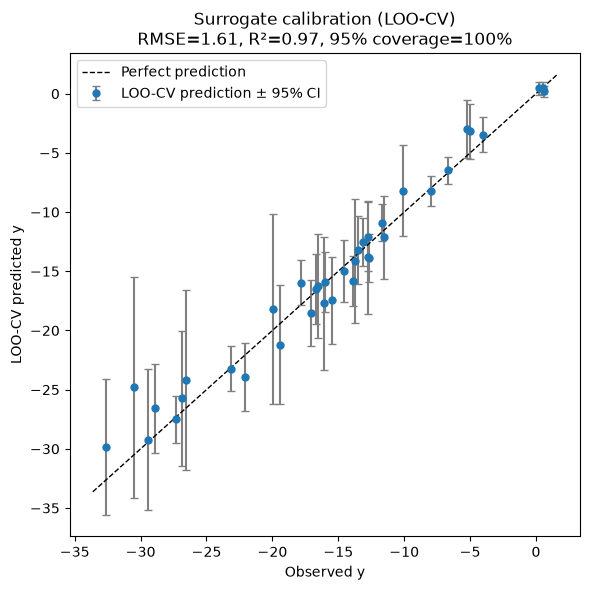

In [5]:
# ----------------------------------------------------------------------------
# 4. Surrogate validation: leave-one-out cross-validation (LOO-CV)
# ----------------------------------------------------------------------------

loo_mean = np.zeros(n)
loo_std = np.zeros(n)
fixed_kernel = gp.kernel_  # reuse optimised hyperparameters, no re-optimisation
for i in range(n):
    mask = np.ones(n, dtype=bool)
    mask[i] = False
    gp_loo = GaussianProcessRegressor(kernel=fixed_kernel, optimizer=None,
                                       normalize_y=False)
    gp_loo.fit(X[mask], y_train[mask])
    m, s = gp_loo.predict(X[i:i + 1], return_std=True)
    loo_mean[i], loo_std[i] = m[0], s[0]

loo_mean_raw = from_standard(loo_mean)
loo_std_raw = loo_std * y_std
resid = y - loo_mean_raw
rmse = np.sqrt(np.mean(resid ** 2))
r2 = 1 - np.sum(resid ** 2) / np.sum((y - y.mean()) ** 2)
z = resid / loo_std_raw  # standardised residuals; should be ~N(0,1) if well-calibrated
coverage_95 = np.mean(np.abs(z) <= 1.96)
print(f"\nLOO-CV: RMSE = {rmse:.3f}, R^2 = {r2:.3f}, "
      f"95% interval empirical coverage = {coverage_95*100:.0f}% "
      "(target 95%)")

print('\n')
# Plot 1: LOO-CV predicted vs actual, with 95% CI error bars
fig, ax = plt.subplots(figsize=(6, 6))
order = np.argsort(y)
ax.errorbar(y[order], loo_mean_raw[order], yerr=1.96 * loo_std_raw[order],
            fmt="o", ecolor="gray", capsize=3, markersize=5,
            label="LOO-CV prediction ± 95% CI")
lims = [min(y.min(), loo_mean_raw.min()) - 1, max(y.max(), loo_mean_raw.max()) + 1]
ax.plot(lims, lims, "k--", lw=1, label="Perfect prediction")
ax.set_xlabel("Observed y")
ax.set_ylabel("LOO-CV predicted y")
ax.set_title(f"Surrogate calibration (LOO-CV)\nRMSE={rmse:.2f}, R²={r2:.2f}, "
             f"95% coverage={coverage_95*100:.0f}%")
ax.legend()
fig.tight_layout()


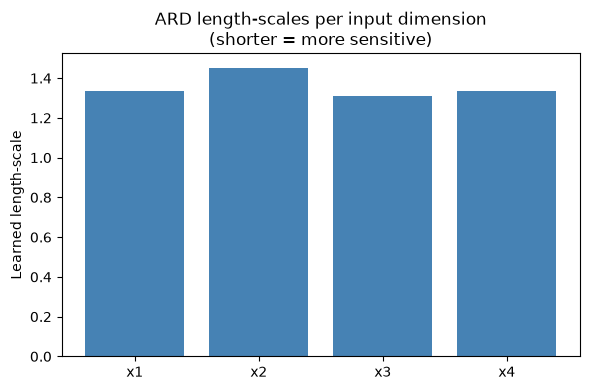

In [6]:
# Plot 2: learned ARD length-scales
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([f"x{j+1}" for j in range(d)], ls, color="steelblue")
ax.set_ylabel("Learned length-scale")
ax.set_title("ARD length-scales per input dimension\n(shorter = more sensitive)")
fig.tight_layout()

In [7]:
# ----------------------------------------------------------------------------
# 5. Acquisition function: Expected Improvement (EI)
# ----------------------------------------------------------------------------

xi = 0.01
f_best = y_train.max()

def expected_improvement(x, gp_model, f_best, xi):
    x = np.atleast_2d(x)
    mu, sigma = gp_model.predict(x, return_std=True)
    sigma = np.maximum(sigma, 1e-9)  # avoid division by zero
    imp = mu - f_best - xi
    zscore = imp / sigma
    ei = imp * norm.cdf(zscore) + sigma * norm.pdf(zscore)
    ei[sigma < 1e-9] = 0.0
    return ei

def neg_ei(x, gp_model, f_best, xi):
    return -expected_improvement(x, gp_model, f_best, xi)[0]



In [8]:
# ----------------------------------------------------------------------------
# 6. Propose the next query point: multi-start optimisation of EI
# ----------------------------------------------------------------------------
# The EI surface is often multi-modal, so we run L-BFGS-B from many random
# restarts (drawn with our seeded Generator) and keep the best optimum found.
N_RESTARTS = 200
x0s = rng.uniform(BOUNDS[:, 0], BOUNDS[:, 1], size=(N_RESTARTS, d))

best_x, best_val = None, np.inf
for x0 in x0s:
    res = minimize(neg_ei, x0, args=(gp, f_best, xi), bounds=BOUNDS,
                    method="L-BFGS-B")
    if res.fun < best_val:
        best_val, best_x = res.fun, res.x

next_x = best_x
next_ei = -best_val
next_mu, next_sigma = gp.predict(next_x.reshape(1, -1), return_std=True)
next_mu_raw = from_standard(next_mu)[0]
next_sigma_raw = next_sigma[0] * y_std

print("\n" + "=" * 70)
print("RECOMMENDED NEXT QUERY POINT (maximising Expected Improvement)")
print("=" * 70)
print(f"x* = {np.round(next_x, 5).tolist()}")
print(f"Expected Improvement at x* : {next_ei:.5f} (standardised units)")
print(f"GP posterior mean predicted y : {next_mu_raw:.3f}")
print(f"GP posterior std  predicted y : {next_sigma_raw:.3f}")
best_idx = np.argmax(y)
print(f"\nCurrent best observed point (row {best_idx+1}): "
      f"x = {np.round(X[best_idx], 5).tolist()}, y = {y[best_idx]:.5f}")


RECOMMENDED NEXT QUERY POINT (maximising Expected Improvement)
x* = [0.42261, 0.37264, 0.40639, 0.42661]
Expected Improvement at x* : 0.00509 (standardised units)
GP posterior mean predicted y : 0.522
GP posterior std  predicted y : 0.251

Current best observed point (row 31): x = [0.4271, 0.39084, 0.36269, 0.41212], y = 0.57984


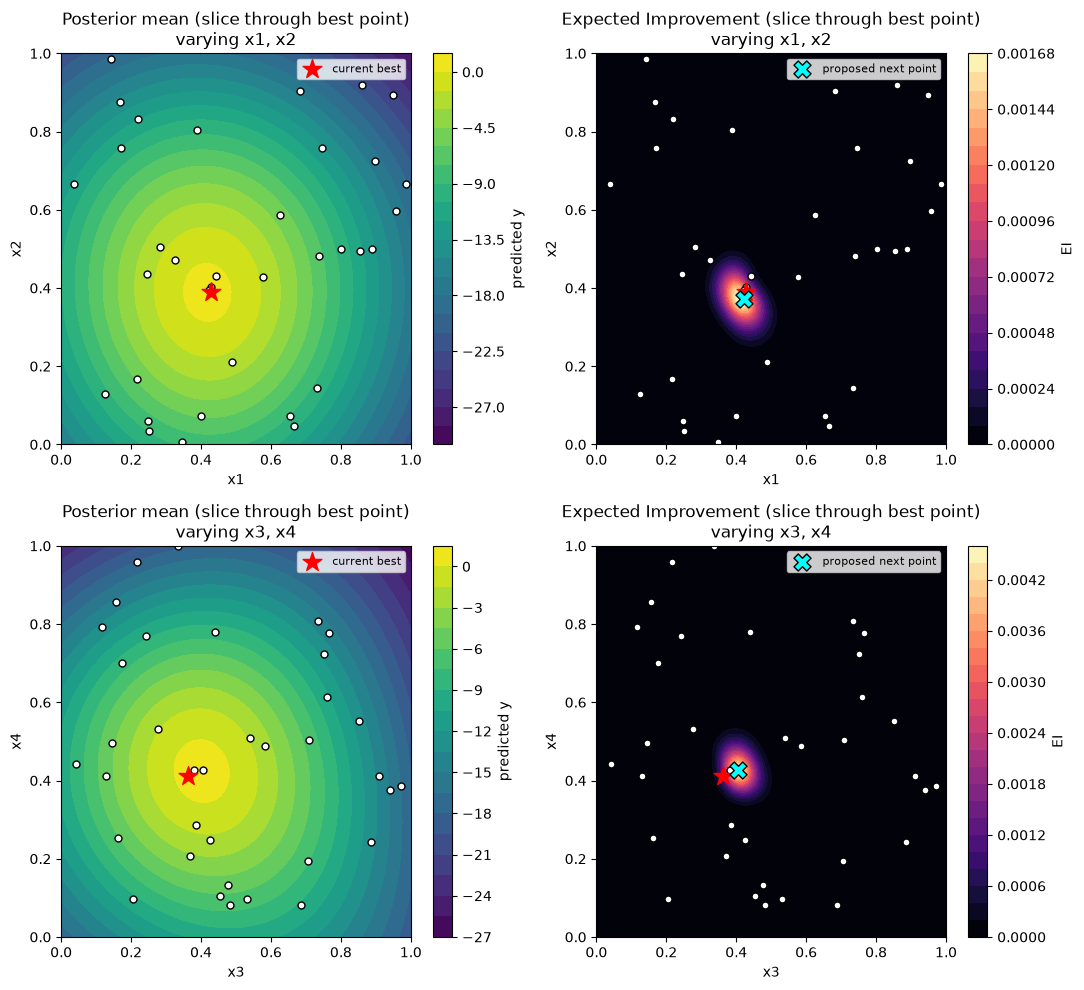

In [9]:
# Plot 3: 2D slices of posterior mean & EI through the best point
# We can only visualise 2 of the 4 dimensions at a time; we fix the other two
# coordinates at the best-so-far point (and, separately, at the newly
# proposed point) and sweep a grid over each pair of dimensions.
grid_n = 80
lin = np.linspace(0, 1, grid_n)
pairs = [(0, 1), (2, 3)]  # (x1,x2) slice and (x3,x4) slice
fixed_point = X[best_idx]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row_i, (i, j) in enumerate(pairs):
    Gi, Gj = np.meshgrid(lin, lin)
    grid = np.tile(fixed_point, (grid_n * grid_n, 1))
    grid[:, i] = Gi.ravel()
    grid[:, j] = Gj.ravel()

    mu_grid, sigma_grid = gp.predict(grid, return_std=True)
    mu_grid_raw = from_standard(mu_grid).reshape(grid_n, grid_n)
    ei_grid = expected_improvement(grid, gp, f_best, xi).reshape(grid_n, grid_n)

    ax_mu = axes[row_i, 0]
    cf = ax_mu.contourf(Gi, Gj, mu_grid_raw, levels=25, cmap="viridis")
    ax_mu.scatter(X[:, i], X[:, j], c="white", edgecolor="black", s=25)
    ax_mu.scatter(fixed_point[i], fixed_point[j], marker="*", c="red", s=200,
                  label="current best")
    ax_mu.set_xlabel(f"x{i+1}")
    ax_mu.set_ylabel(f"x{j+1}")
    ax_mu.set_title(f"Posterior mean (slice through best point)\n"
                     f"varying x{i+1}, x{j+1}")
    fig.colorbar(cf, ax=ax_mu, label="predicted y")
    ax_mu.legend(loc="upper right", fontsize=8)

    ax_ei = axes[row_i, 1]
    cf2 = ax_ei.contourf(Gi, Gj, ei_grid, levels=25, cmap="magma")
    ax_ei.scatter(X[:, i], X[:, j], c="white", edgecolor="black", s=25)
    ax_ei.scatter(fixed_point[i], fixed_point[j], marker="*", c="red", s=200)
    if abs(next_x[i] - fixed_point[i]) > 1e-9 or abs(next_x[j] - fixed_point[j]) > 1e-9:
        ax_ei.scatter(next_x[i], next_x[j], marker="X", c="cyan", s=150,
                      edgecolor="black", label="proposed next point")
    ax_ei.set_xlabel(f"x{i+1}")
    ax_ei.set_ylabel(f"x{j+1}")
    ax_ei.set_title(f"Expected Improvement (slice through best point)\n"
                     f"varying x{i+1}, x{j+1}")
    fig.colorbar(cf2, ax=ax_ei, label="EI")
    ax_ei.legend(loc="upper right", fontsize=8)

fig.tight_layout()

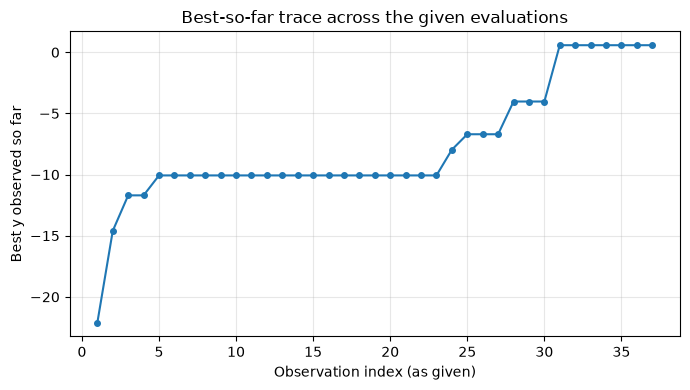

In [10]:
# Plot 4: best-observed-so-far trace (as if points arrived in this order)
fig, ax = plt.subplots(figsize=(7, 4))
running_best = np.maximum.accumulate(y)
ax.plot(np.arange(1, n + 1), running_best, marker="o", markersize=4)
ax.set_xlabel("Observation index (as given)")
ax.set_ylabel("Best y observed so far")
ax.set_title("Best-so-far trace across the given evaluations")
ax.grid(alpha=0.3)
fig.tight_layout()